In [2]:
import json
import math
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

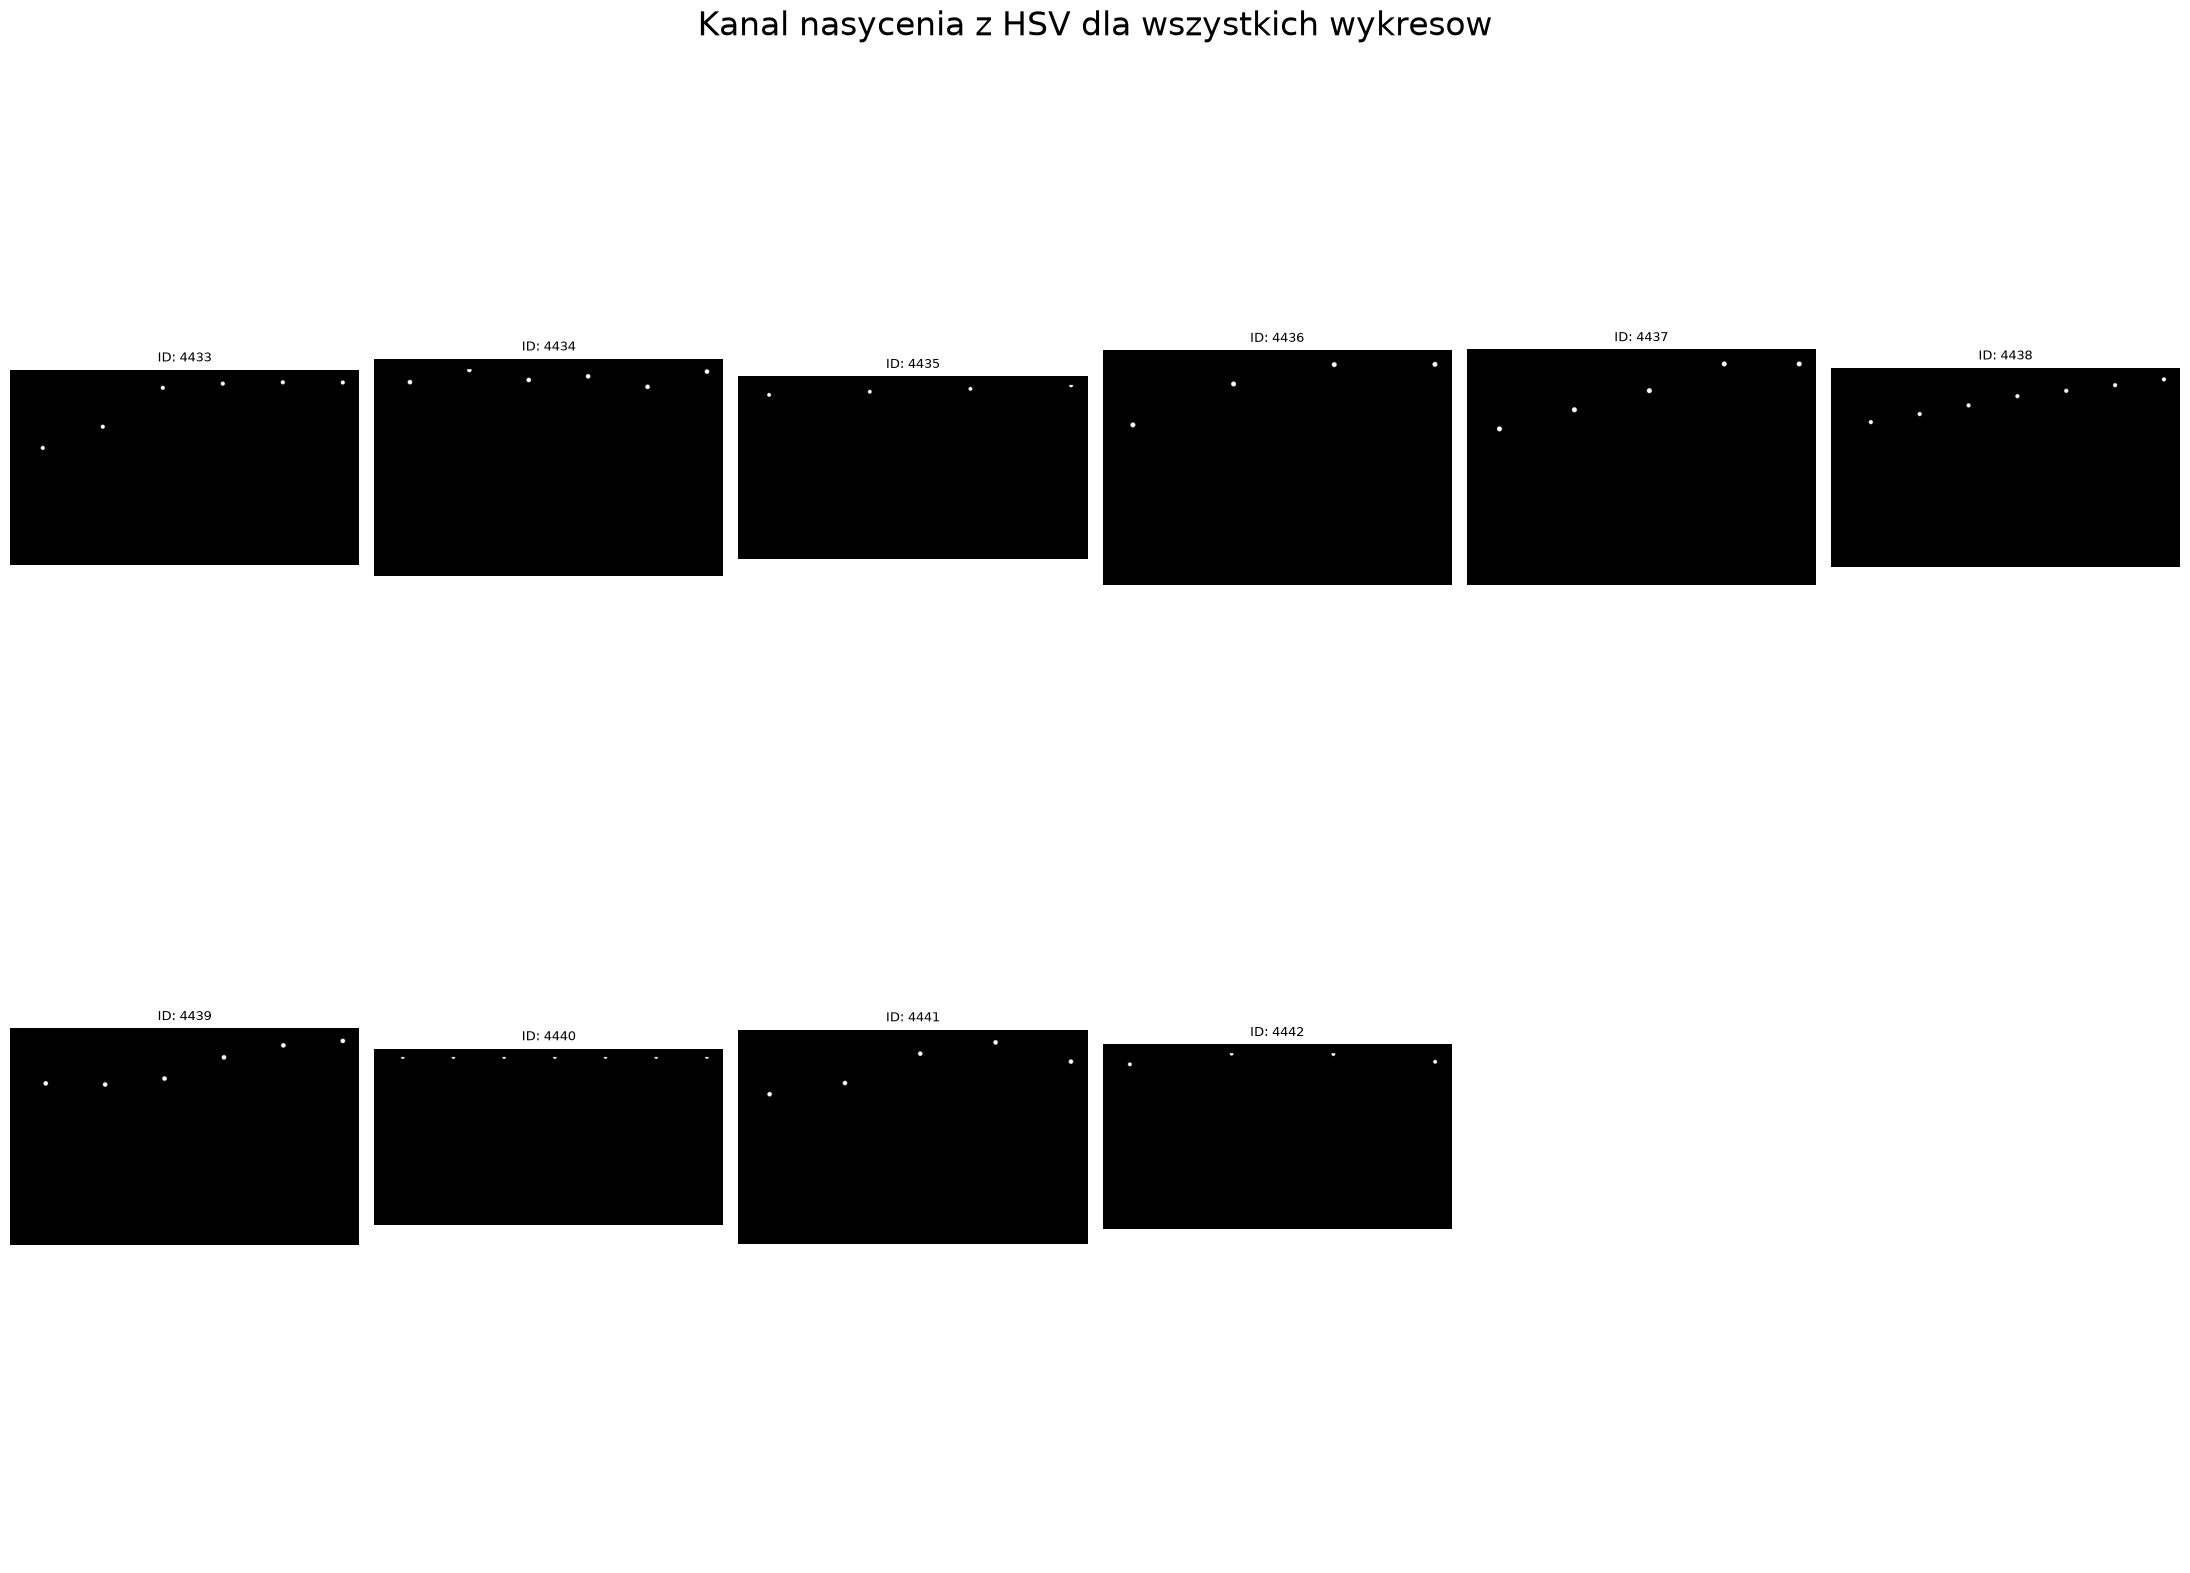

In [10]:
with open(os.path.join("..", "data", "sample_annotations.json"), 'r', encoding='utf-8') as f:
    meta = json.load(f)

dev_ids = meta['dev_ids']
cols=6
rows = math.ceil(len(dev_ids) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(22, 16))
axes = axes.flatten()

for i, dev_id in enumerate(dev_ids):
    img_path = os.path.join("..", "data", "sample_images", f"{dev_id}.png")
    img = cv2.imread(img_path)

    ax = axes[i]
    if img is not None:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        saturation_channel = hsv[:, :, 1]

        ax.imshow(saturation_channel, cmap="gray")
        ax.set_title(f"ID: {dev_id}", fontsize=9)
    else:
        ax.text(0.5, 0.5, "Brak pliku", ha="center", va="center")

    ax.axis("off")


for j in range(len(dev_ids), len(axes)):
    axes[j].axis("off")

plt.suptitle("Kanal nasycenia z HSV dla wszystkich wykresow", fontsize=24)

plt.tight_layout()
plt.show()


In [11]:
images_dir = os.path.join("..", "data", "sample_images")
files = sorted([f for f in os.listdir(images_dir) if f.endswith(".png")])

print("--- ANALIZA NASYCENIA WSZYSTKICH WYKRESÓW ---")
for f in files:
    img = cv2.imread(os.path.join(images_dir, f))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    max_sat = np.max(hsv[:, :, 1])
    color_pixels = np.sum(hsv[:, :, 1] > 50)

    # Obrazy z bardzo niskim nasyceniem to wykresy szare/monochromatyczne
    chart_type = "KOLOROWY" if color_pixels > 50 else "SZARY / MONOCHROMATYCZNY"
    print(
        f"Plik: {f:<10} | Max Saturation: {max_sat:<3} | Color Pixels:"
        f" {color_pixels:<4} -> {chart_type}"
    )

--- ANALIZA NASYCENIA WSZYSTKICH WYKRESÓW ---
Plik: 4433.png   | Max Saturation: 133 | Color Pixels: 918  -> KOLOROWY
Plik: 4434.png   | Max Saturation: 218 | Color Pixels: 896  -> KOLOROWY
Plik: 4435.png   | Max Saturation: 255 | Color Pixels: 575  -> KOLOROWY
Plik: 4436.png   | Max Saturation: 86  | Color Pixels: 572  -> KOLOROWY
Plik: 4437.png   | Max Saturation: 255 | Color Pixels: 796  -> KOLOROWY
Plik: 4438.png   | Max Saturation: 255 | Color Pixels: 1090 -> KOLOROWY
Plik: 4439.png   | Max Saturation: 193 | Color Pixels: 928  -> KOLOROWY
Plik: 4440.png   | Max Saturation: 170 | Color Pixels: 533  -> KOLOROWY
Plik: 4441.png   | Max Saturation: 228 | Color Pixels: 783  -> KOLOROWY
Plik: 4442.png   | Max Saturation: 198 | Color Pixels: 519  -> KOLOROWY
Plik: 4443.png   | Max Saturation: 208 | Color Pixels: 617  -> KOLOROWY
Plik: 4444.png   | Max Saturation: 235 | Color Pixels: 464  -> KOLOROWY
Plik: 4445.png   | Max Saturation: 62  | Color Pixels: 628  -> KOLOROWY
Plik: 4446.png   |